<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/3_4_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 3.4: Logistic Regression

## Topics:

*   Sigmoid/logistic function
*   Binary classification probabilities
*   Logistic regression fitting and interpretation

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)

# 3.4.1 Sigmoid/Logistic function

The sigmoid function is $$\sigma(z) = \frac{1}{1 + e^{-z}}$$ defined for every real $z$. Its output is always in $(0, 1)$, so it can be read as a probability.

Its inverse is the logit (log-odds):
$$z = \ln\left(\frac{p}{1 - p}\right)$$
In logistic regression, $z = \beta_0 + \beta_1 x$ and $\sigma(z) = P(y = 1 \mid x)$.
Symmetry property: $\sigma(-z) = 1 - \sigma(z)$.

In [37]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

z_vals = np.array([-6, -4, -2, -1, 0, 1, 2, 4, 6])
probs = sigmoid(z_vals)

print("  z    sigmoid(z)")
for z, p in zip(z_vals, probs):
    print(f"{z:3d}    {p:.4f}")

# check that every output is strictly between 0 and 1
print("\nAll values in (0, 1)?", np.all((probs > 0) & (probs < 1)))

# check the symmetry
print("Symmetry sigma(-z) = 1 - sigma(z)?", np.allclose(sigmoid(-z_vals), 1 - probs))

# check the logit undoes the sigmoid
logit = np.log(probs / (1 - probs))
print("log(p/(1-p)) recovers z?", np.allclose(logit, z_vals))

  z    sigmoid(z)
 -6    0.0025
 -4    0.0180
 -2    0.1192
 -1    0.2689
  0    0.5000
  1    0.7311
  2    0.8808
  4    0.9820
  6    0.9975

All values in (0, 1)? True
Symmetry sigma(-z) = 1 - sigma(z)? True
log(p/(1-p)) recovers z? True


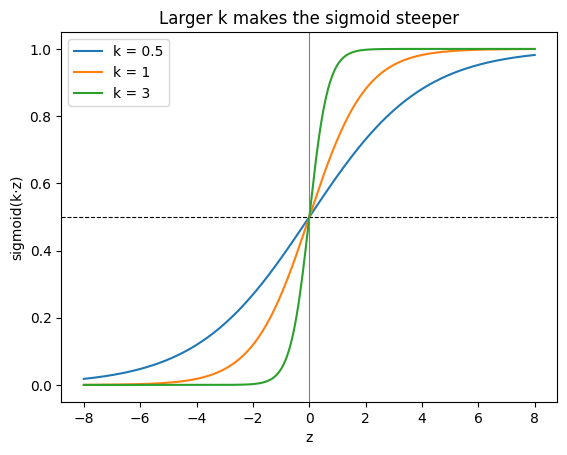

In [38]:
z = np.linspace(-8, 8, 300)

for k in [0.5, 1, 3]:
    plt.plot(z, sigmoid(k * z), label=f"k = {k}")

plt.axhline(0.5, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(k·z)")
plt.title("Larger k makes the sigmoid steeper")
plt.legend()
plt.show()

The table shows that the sigmoid turns any real number into a value strictly between $0$ and $1$: large negative $z$ gives values near 0, large positive $z$ gives values near 1, and $\sigma(0) = 0.5$ exactly.

The checks confirm the symmetry $\sigma(-z) = 1 - \sigma(z)$ and that the log-odds $\ln\left(\frac{p}{1-p}\right)$ recovers the original $z$, so the logit is the inverse of the sigmoid.

In the plot, the increasing $k$ makes the curve steeper, which means the predicted probability switches from unlikely to likely much faster around $z = 0$.

# 3.4.2 Binary Classification Probability

In binary classification, every exmaple belongs to one of 2 classes, $y = 0$ or $y = 1.$

Instead of only assigning a label, a probabilistic classifier
gives each point a probability of belonging to class 1, written $P(y = 1 \mid x)$. Since there are only
two classes, the probability of class 0 is $P(y = 0 \mid x) = 1 - P(y = 1 \mid x)$, so the two always add
to 1.

To turn a probability into a prediction, we use a threshold, usually 0.5: points with
$P(y = 1 \mid x) > 0.5$ are predicted as class 1, and the rest as class 0.

The probability also tells us
how confident the model is. Values near 0 or 1 mean the model is very sure, and values near 0.5 mean it is uncertain.



In [39]:
# sigmoid function (from Section 1)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# create the data and fit the model
X, y = make_classification(n_samples=120, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=0.8, random_state=422)
model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))

Coefficients: [[1.0155 3.3077]]
Intercept: [1.9411]
Training accuracy: 0.9333333333333333
Confusion matrix:
[[59  1]
 [ 7 53]]


predict_proba matches sigmoid(z)? True
Probabilities sum to 1? True
Prediction = (P > 0.5)? True

     z      P(y=1)  predicted  actual
 -1.282   0.2172      0        0
  1.838   0.8627      1        1
  4.191   0.9851      1        1
 -3.086   0.0437      0        0
  2.484   0.9230      1        1


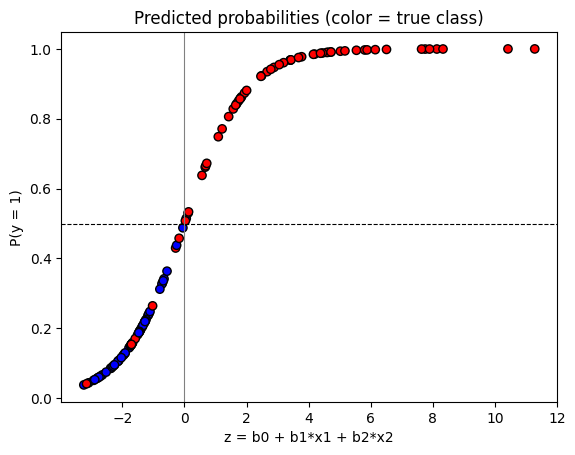

In [40]:
# linear score z for every point
z = X @ model.coef_[0] + model.intercept_[0]

# check predict_probability is just the sigmoid of z
print("predict_proba matches sigmoid(z)?", np.allclose(proba, sigmoid(z)))

# P(y=0) + P(y=1) = 1 for every point
print("Probabilities sum to 1?", np.allclose(model.predict_proba(X).sum(axis=1), 1))

# predicted class is 1 exactly when P(y=1) > 0.5
print("Prediction = (P > 0.5)?", np.all(pred == (proba > 0.5)))

print("\n     z      P(y=1)  predicted  actual")
for i in range(5):
    print(f"{z[i]:7.3f}   {proba[i]:.4f}      {pred[i]}        {y[i]}")

# every point sits on the sigmoid curve
plt.scatter(z, proba, c=y, cmap="bwr", edgecolor="k")
plt.axhline(0.5, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("z = b0 + b1*x1 + b2*x2")
plt.ylabel("P(y = 1)")
plt.title("Predicted probabilities (color = true class)")
plt.show()

The checks confirm that the probabilites from predict_proba are exactly $\sigma(z)$ for the model's linear score $z$, that $P(y=0) + P(y=1) = 1$ for every point, and that
the model predicts class 1 exactly when $P(y = 1) > 0.5$.

In the plot, every point lies on the
sigmoid curve: blue points (class 0) mostly sit below 0.5 and red points (class 1) mostly sit
above it.

Points on the wrong side of the dashed line are the misclassified ones counted in the matrix. Points near 0.5 are the ones the model is least sure about.

# 3.4.3 Logistic regression fitting and interpretation

Fitting a logistic regression model means choosing the coefficients $\beta_0, \beta_1, \beta_2$ in
$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2$ that best match the data.

The model does this by maximizing the likelihood, which means picking the coefficients that make the labels probable. Once the model is fit, the coefficients can be interepreted through log-odds:
$$\ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 x_1 + \beta_2 x_2$$

So increasing $x_1$ by 1 changes the log-odds by $\beta_1$. Equivalently, it
multiplies the odds by $e^{\beta_1}$, which is also called the odds ratio. A positive coefficient raises the
probability of class 1, and a negative one lowers it. The **decision boundary** is where $p = 0.5$
(that is, $z = 0$), which is a straight line in the $(x_1, x_2)$ plane.

Fitted model: z = 1.9411 + 1.0155*x1 + 3.3077*x2
Odds ratios (e^b1, e^b2): [ 2.7608 27.3231]

P(y=1) before: 0.2172, after x1 + 1: 0.4338
Ratio from predictions: 2.7608   e^b1: 2.7608
Match? True


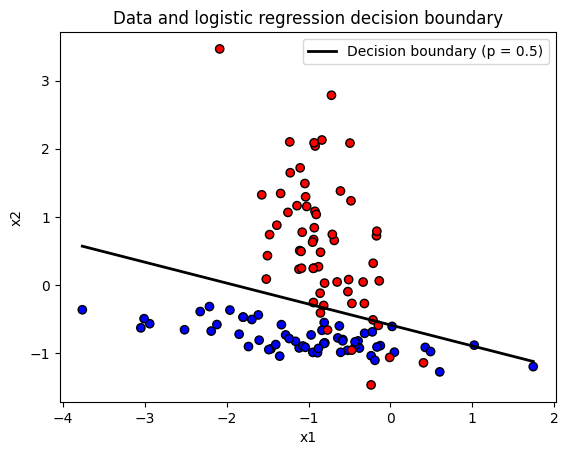

In [41]:
# data/model same as section 2
X, y = make_classification(n_samples=120, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=0.8, random_state=422)
model = LogisticRegression()
model.fit(X, y)

# coefficients
b0 = model.intercept_[0]
b1, b2 = model.coef_[0]
print(f"Fitted model: z = {b0:.4f} + {b1:.4f}*x1 + {b2:.4f}*x2")
print("Odds ratios (e^b1, e^b2):", np.exp(model.coef_[0]))

# increasing x1 by 1 multiplies the odds by e^b1
x = X[:1].copy()
p_before = model.predict_proba(x)[0, 1]
x[0, 0] += 1
p_after = model.predict_proba(x)[0, 1]
ratio = (p_after / (1 - p_after)) / (p_before / (1 - p_before))
print(f"\nP(y=1) before: {p_before:.4f}, after x1 + 1: {p_after:.4f}")
print(f"Ratio from predictions: {ratio:.4f}   e^b1: {np.exp(b1):.4f}")
print("Match?", np.isclose(ratio, np.exp(b1)))

# simple plot: data points and the decision boundary line (z = 0)
x1_line = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
x2_line = -(b0 + b1 * x1_line) / b2

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolor="k")
plt.plot(x1_line, x2_line, color="black", linewidth=2, label="Decision boundary (p = 0.5)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Data and logistic regression decision boundary")
plt.legend()
plt.show()

The printed equation shows the fitted coefficients, and the check confirms that increasing $x_1$ by 1 multiplies the odds of class 1 by exactly $e^{\beta_1}$, as the log-odds predicts.

In the plot, the black line is the decision boundary where $z = 0$ ($p = 0.5$) which was found by solving $\beta_0 + \beta_1 x_1 + \beta_2 x_2 = 0$ for $x_2$.

Points on one side are predicted as class 0 and points on the other as class 1. Points of the wrong color on a side are misclassified and points close to the line are the ones the model is least certain about.

# Reflection



*   Sigmoid/logistic function: Defined $\sigma(z) = \frac{1}{1 + e^{-z}}$ and printed its values for $z$ from $-6$ to $6$, which went from 0.0025 up to 0.9975, with $\sigma(0) = 0.5$ exactly. Checked that every output was between 0 and 1, that $\sigma(-z) = 1 - \sigma(z)$, and that the logit $\ln\left(\frac{p}{1-p}\right)$ recovered the original $z$. Plotting $\sigma(kz)$ for $k = 0.5, 1, 3$ showed that a larger $k$ makes the curve steeper.

*   Binary Classification probabilities: Fit a logistic regression model to 120 points and changed `class_sep` from 1.2 to 0.8 so the classes overlap more. The training accuracy was 0.9333. The checks showed that the model's probabilities come from the sigmoid, that $P(y=0) + P(y=1) = 1$, and that the model predicts class 1 when $P(y=1) > 0.5$.

*   Logistic regression fitting and interpretation: The fitted model was $z = 1.9411 + 1.0155x_1 + 3.3077x_2$. Both coefficients are positive, so larger $x_1$ or $x_2$ makes class 1 more likely. Increasing $x_1$ by 1 multiplies the odds by $e^{1.0155} \approx 2.76$. The plot showed the decision boundary as a straight line separating the two predicted classes.
